## <span style="background-color:#FFE6E6"> 1. RNN의 한계 </span>


### <span style="color:violet"> 1-1 Attention의 등장 </span>
> Seq2Seq의 디코더는 고정된 크기의 컨텍스트 벡터 하나만 참고함 (병목 현상) <br>
→ 문장이 길수록 정보가 손실되고, 출력 단어마다 필요한 정보를 다르게 반영할 수 없음.

- 컨텍스트 벡터는 인코더의 마지막 은닉 상태라서 마지막 단어 정보는 진하고, 앞쪽 단어 정보는 희미함.

> Attention: 현재 시점에서 가장 중요한 부분에 더 높은 가중치를 주는 기술 <br>
디코더가 단어를 만들 때마다 입력 문장 전체를 다시 보고, **출력 단어마다 새 컨텍스트 벡터**를 만듦.
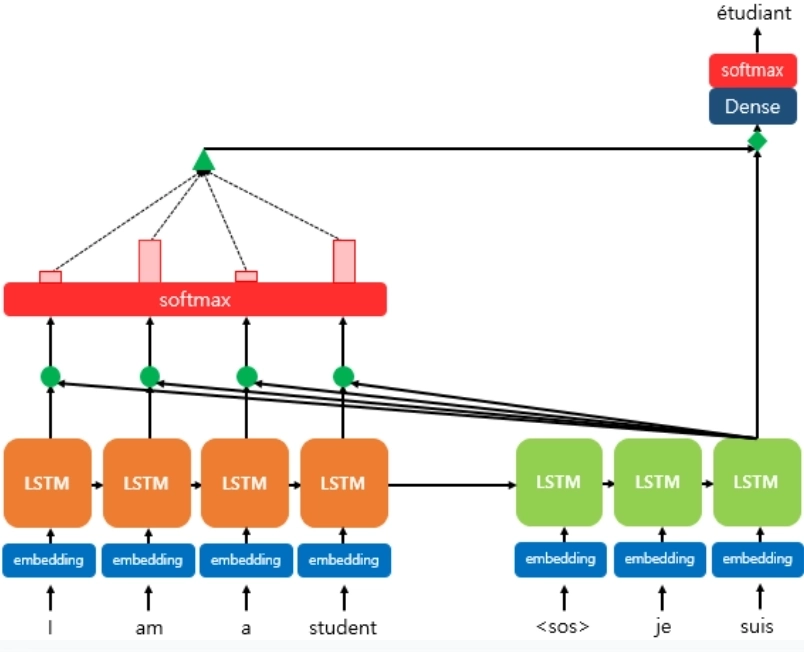

> attention의 과정
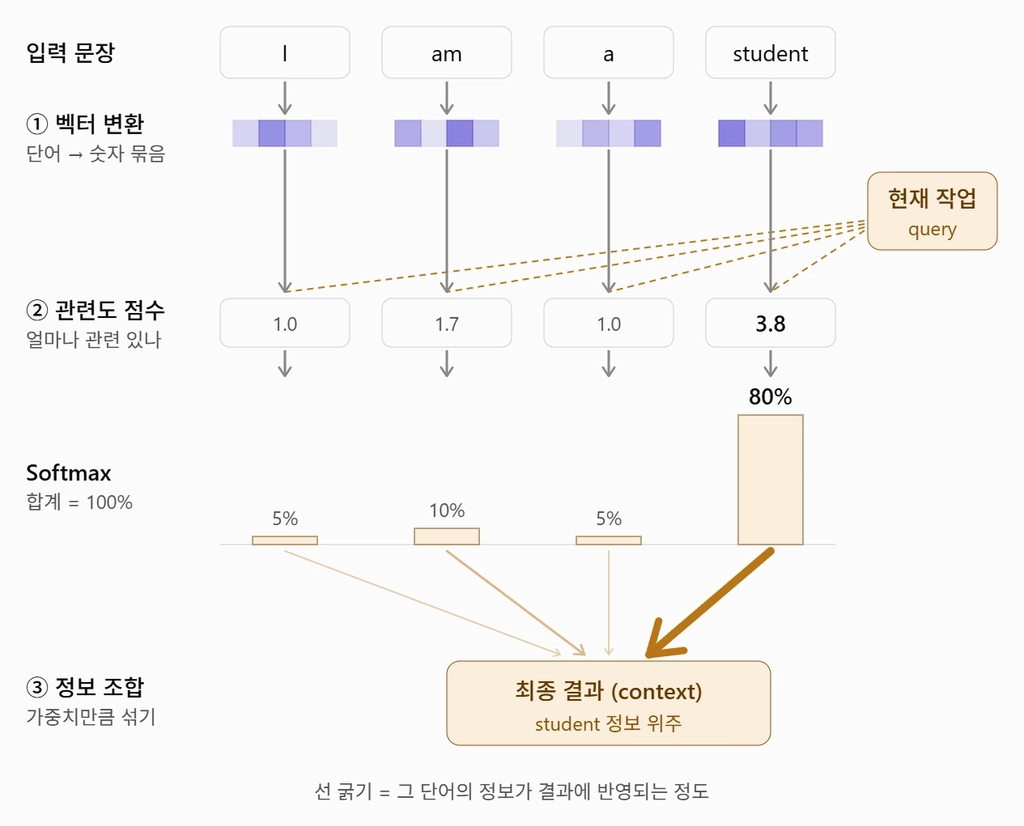
1. 인코더의 hidden state를 마지막 하나가 아니라 전부 남겨 둠.
2. 디코더의 현재 상태와 각 단어의 관련도 점수를 계산하고, Softmax로 합이 1인 비율(가중치)로 바꿈.
    - ex. student 3.8점 → 80% 집중
3. 가중치만큼 hidden state를 섞어 컨텍스트 벡터를 만들고, 다음 단어를 출력함.

| 장점 | 비교 대상의 한계 | Attention |
| --- | --- | --- |
| 시간 유연성 | RNN: 멀수록 정보가 흐려짐 | 모든 단어를 직접 비교해 거리와 무관 |
| 공간 유연성 | CNN: 필터 크기만큼 주변만 봄 | 모든 위치를 한 번에 연결 |
| 병렬화 | RNN: 앞 단계가 끝나야 다음 계산 | 단어 쌍마다 독립이라 동시 계산 가능 |

- 단, 인코더와 디코더가 여전히 LSTM이라 전체 병렬화는 불가함. → Attention은 RNN의 **보조 역할**에 그침.


### <span style="color:violet"> 1-2 Attention is All You Need </span>
> 2017년 Google 연구진이 Transformer를 처음 제안한 논문. 오늘날 LLM의 기반

- 배경: RNN 계열은 n번째 단어를 계산하려면 n-1번째 결과가 필요해 병렬 처리가 불가능함.
- 핵심 발견: 순환(RNN)과 합성곱(CNN)은 필수가 아님. Attention만으로 성능이 더 좋고, 병렬화로 학습이 빨라짐.
- 파급효과: 디코더를 쌓은 GPT, 인코더를 쌓은 BERT 등장. 이미지, 음성 분야로도 확장됨.

> 트랜스포머: 단어를 순서대로 처리하지 않고, Attention만으로 문장 전체를 한 번에 처리하는 인코더-디코더 모델 <br>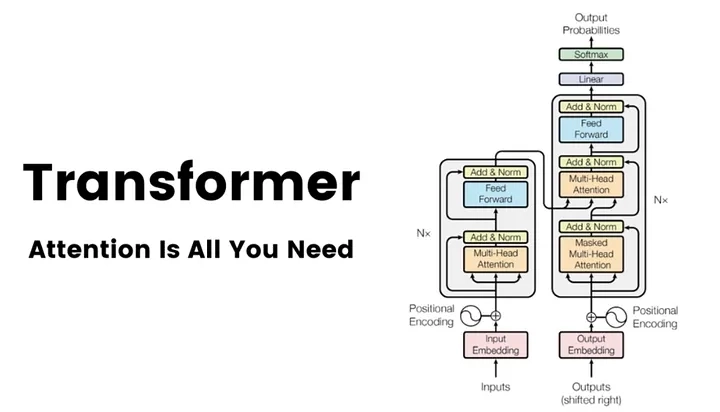
인코더(입력 이해)와 디코더(출력 생성)를 각각 N개 층으로 쌓음.

| 구분 | Seq2Seq + Attention | Transformer |
| --- | --- | --- |
| 인코더, 디코더 내부 | LSTM (순차 처리) | Self-Attention |
| 어텐션의 역할 | RNN을 돕는 보조 | 모델 그 자체 |
| 어텐션 사용 위치 | 디코더 → 인코더 1곳 | 인코더 내부, 디코더 내부, 인코더-디코더 사이 3곳 |
| 순서 정보 | RNN이 읽으며 반영 | Positional Encoding으로 추가 |
| 병렬 처리 | 불가 | 가능 |


## <span style="background-color:#FFE6E6"> 2. Self-Attention </span>


### <span style="color:violet"> 2-1 Query, Key, Value </span>
> Attention은 Query를 Key들과 비교해 관련도를 구하고, 그 비율만큼 Value를 섞어 결과를 만드는 계산 <br>
LSTM은 기억 전달 방식만 개선했고, Transformer는 순서대로 전달하는 대신 모든 단어를 직접 비교함.

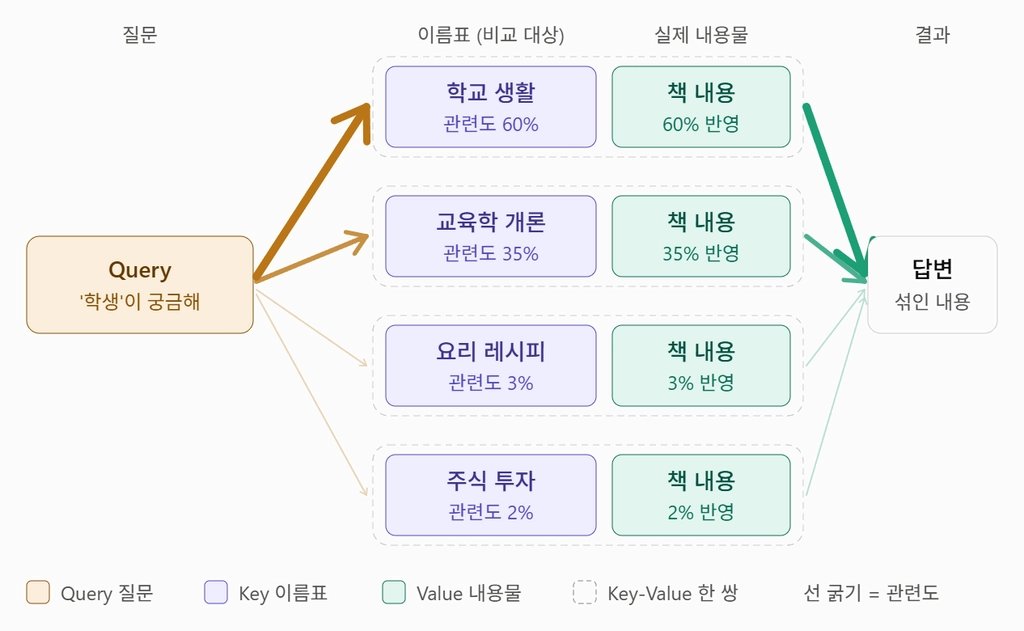
| 구분 | 역할 | 도서관 비유 |
| --- | --- | --- |
| Query | 현재 단어가 "나한테 필요한 정보가 뭐지?"라고 묻는 벡터 | "'학생'에 대해 알고 싶어" |
| Key | 각 단어가 "나는 이런 정보를 가졌어"라고 보이는 이름표 | 책 제목표: 학교 생활 60%, 교육학 개론 35%, 요리 3%, 주식 2% |
| Value | 각 단어가 실제로 전달하는 정보. 관련도 비율만큼 섞음 | 각 책 내용을 비율만큼 섞어 최종 답변 |

- Key와 Value는 한 단어에서 만들어진 한 쌍. Key는 "찾는 기준", Value는 "가져오는 내용".
- 나누는 이유: 관련 여부를 판단할 정보와 실제로 전달할 정보가 다를 수 있기 때문.

### <span style="color:violet"> 2-2 Cross-Attention vs. Self-Attention </span>
> 공통 흐름: Q, K, V 생성 → Q와 K로 관련도 계산 → Softmax로 비율 변환 → 비율만큼 V를 섞음
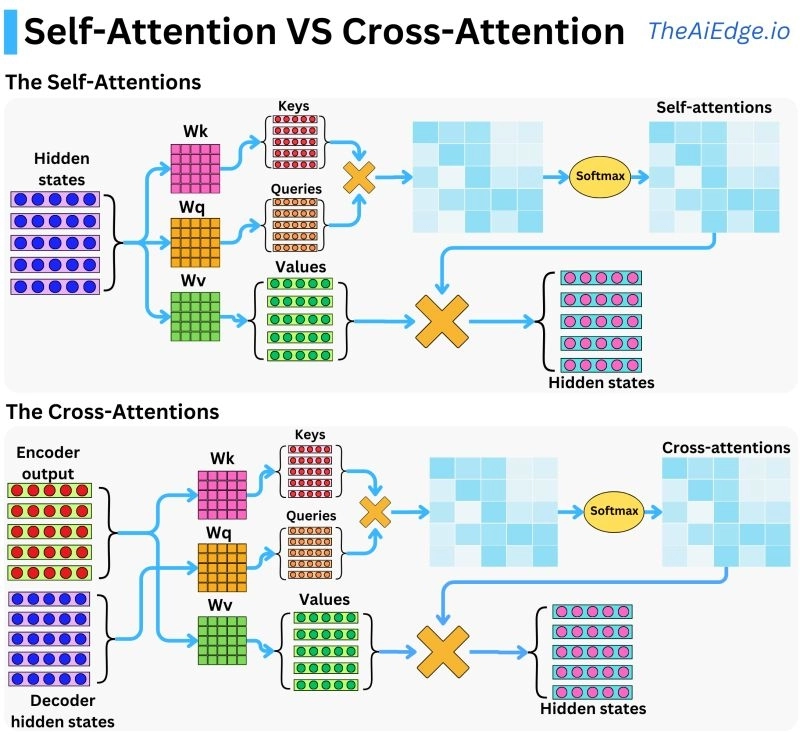

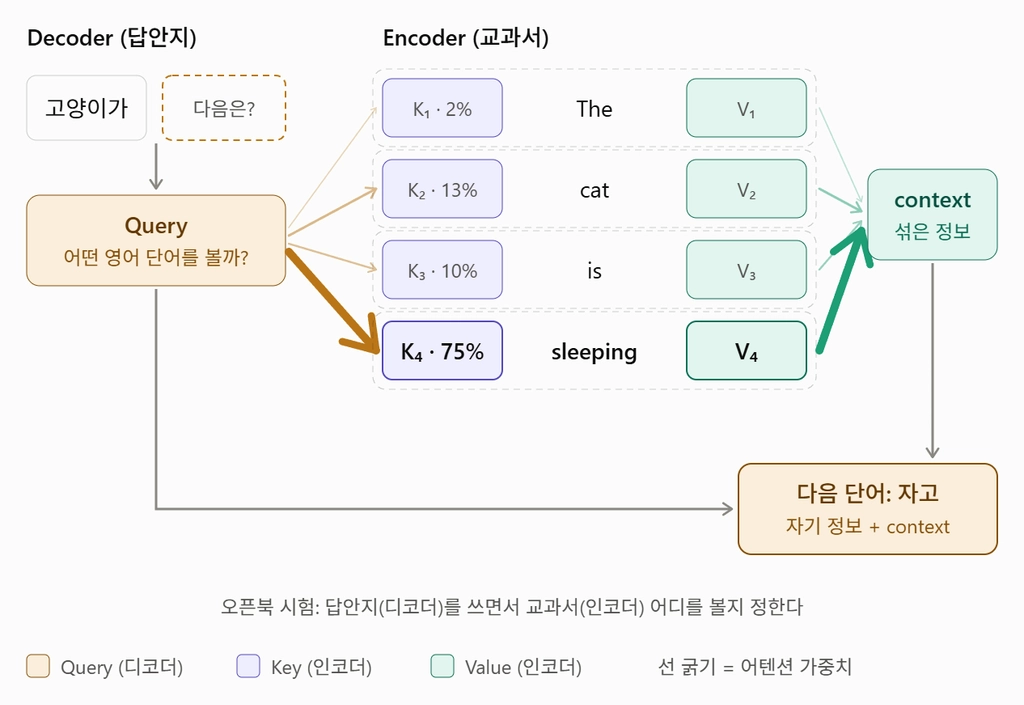
- Cross-Attention: Q는 디코더, K와 V는 인코더에서 옴. "남에게 묻기"
    - ex. "The cat is sleeping" → "고양이가 ___"의 다음 단어를 만들 때 sleeping에 75% 집중해 "자고" 출력.
- Self-Attention: Q, K, V가 모두 같은 문장에서 옴. "나에게 묻기"
    - ex. "가을 은행 냄새 지독해"에서 '은행'이 냄새 45%, 가을 30%를 참고해 "가을에 냄새 나는 열매"라는 의미를 얻음.
    - 모든 단어가 동시에 이 과정을 거침 → 병렬 처리 가능.

| 구분 | Cross-Attention | Self-Attention |
| --- | --- | --- |
| 참조 대상 | 다른 시퀀스 (디코더 → 인코더) | 같은 시퀀스 (문장 내부) |
| 주요 목적 | 고정 컨텍스트 벡터의 병목 해결 | 문맥이 반영된 단어 표현 생성 |
| 기반 | RNN | Transformer |
| 병렬 처리 | RNN 기반이면 불가 | 가능 |

- Transformer는 둘 다 사용함.
    - 인코더: Self-Attention (원문 단어끼리)
    - 디코더: Self-Attention (번역 중인 단어끼리, 뒤쪽 단어는 가림)
    - 인코더-디코더 사이: Cross-Attention (원문 참고)

### <span style="color:violet"> 2-3 Scaled Dot-Product Attention </span>
> Query와 Key를 **내적**해 관련도를 구하는 Transformer의 Attention 계산 방식 <br>
내적: 두 벡터가 비슷한 방향일수록 커지는 값 → "얼마나 닮았나"를 숫자로 표현함.
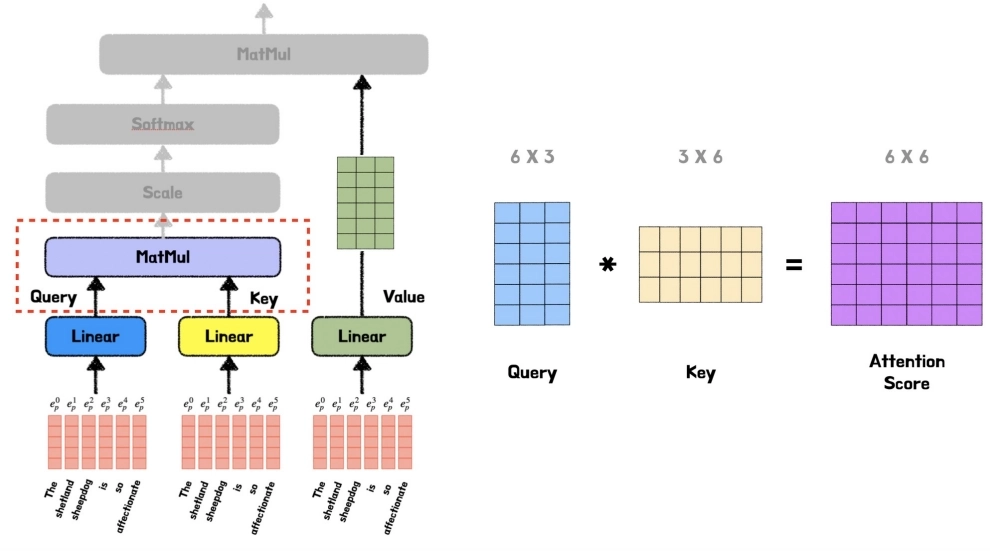


원리
1. 모든 단어의 Query와 Key를 한 번에 내적해 "모든 단어 × 모든 단어" 관련도 표를 만듦. 행렬 곱 한 번으로 동시에 계산 → 병렬 처리가 실제로 일어나는 지점.
2. 점수를 $\sqrt{d_k}$(벡터 차원의 제곱근)로 나눔 (스케일링).
3. Softmax로 각 단어가 다른 단어들을 몇 %씩 참고할지 비율로 바꿈.
4. 비율만큼 Value를 섞어 새 벡터를 만듦.

> 스케일링 이유: 차원이 커지면 내적 값이 너무 커져 Softmax가 한 단어에 몰리고, 기울기 소실이 생김


## <span style="background-color:#FFE6E6"> 3. Multi-Head Attention </span>

### <span style="color:violet"> 3-1 Single-Head Attention vs. Multi-Head Attention </span>
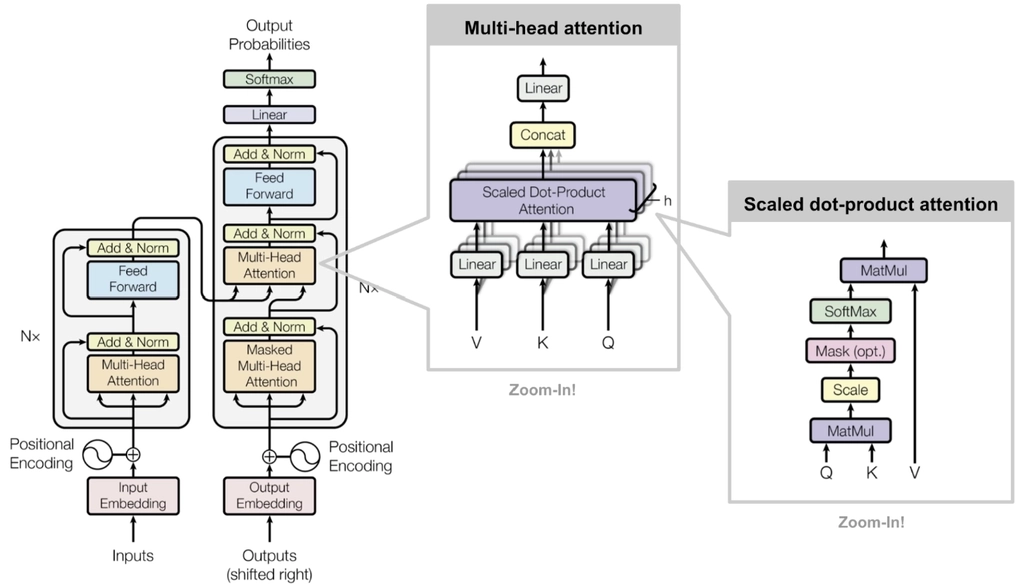
> 헤드: 자기만의 가중치로 Attention을 한 번 계산하는 독립 단위 <br>
헤드마다 가중치가 달라서 같은 문장을 봐도 집중하는 단어가 다름.

- Single-Head: 헤드 1개가 집중력 100%를 여러 관계에 나눠 씀 → 정보가 섞여 흐릿해짐.
- Multi-Head: 헤드마다 각자 100%를 쓰고 결과를 나란히 이어 붙임 → 정보가 또렷하게 남음.

ex. "Tom gave Mary a book yesterday"에서 'gave'

| | Tom | Mary | book | yesterday |
| --- | --- | --- | --- | --- |
| Single-Head | 0.25 | 0.25 | 0.25 | 0.23 |
| Multi-Head | 헤드 1 (Who?) 0.90 | 헤드 2 (To whom?) 0.90 | 헤드 3 (What?) 0.90 | 헤드 4 (When?) 0.90 |

- Single-Head = 기자 1명이 모든 질문을 혼자 취재함. 넓지만 얕음.
- Multi-Head = 기자 8명이 한 분야씩 깊게 취재하고, 편집장이 한 기사로 엮음.

### <span style="color:violet"> 3-2 Multi-Head Attention 작동 방식 </span>
> 논문 기준: 단어 벡터 512차원을 64차원짜리 헤드 8개로 나눠 계산

| 단계 | 하는 일 | 기자 비유 |
| --- | --- | --- |
| ① 분할 | 헤드마다 다른 가중치로 작은 Q, K, V를 8세트 만듦 | 기자 8명에게 취재 수첩 배분 |
| ② 병렬 Attention | 8개 헤드가 동시에, 서로 간섭 없이 Attention 계산 | 각자 자기 분야 취재 |
| ③ 결합 (Concat) | 8개 결과를 한 줄로 이어 붙여 다시 512차원으로 만듦 | 기사 8편을 한 묶음으로 |
| ④ 최종 투영 | 가중치를 한 번 더 곱해 8개 관점을 하나로 융합함 | 편집장이 한 기사로 다듬기 |


## <span style="background-color:#FFE6E6"> 4. Transformer 전체 아키텍처 </span>

### <span style="color:violet"> 4-1 트랜스포머의 전처리 단계 </span>
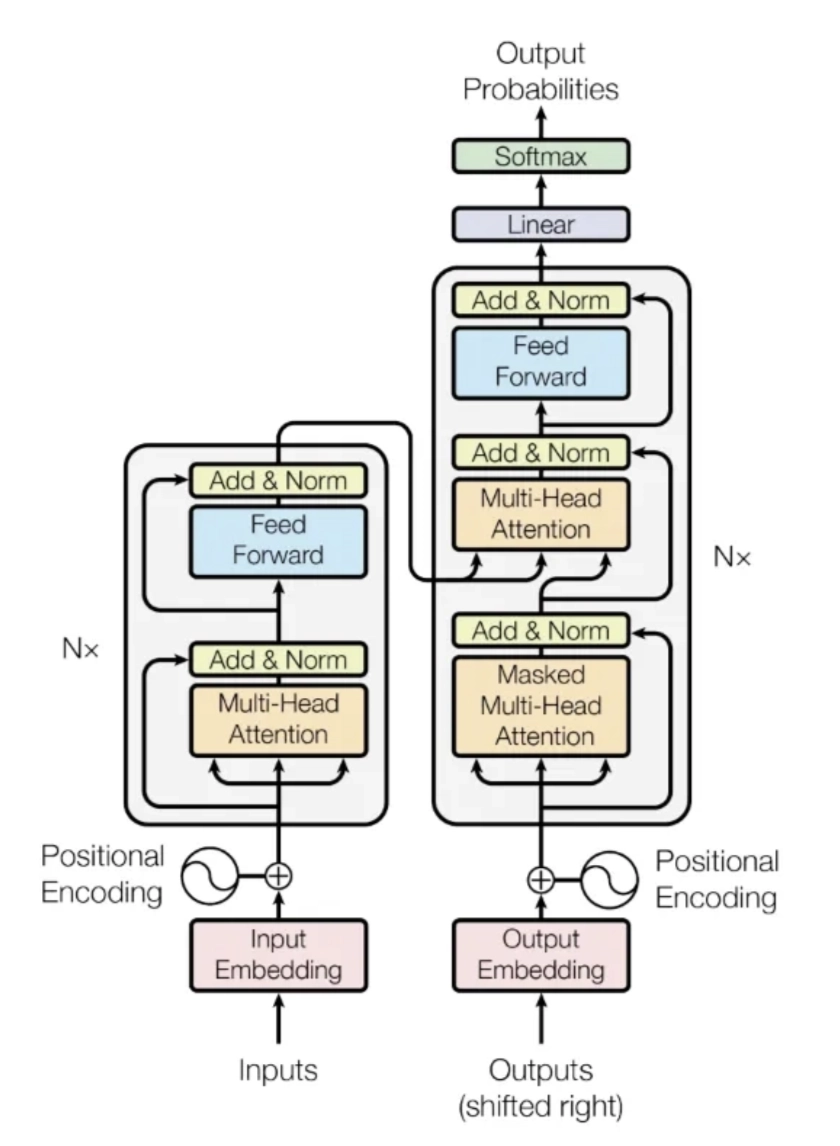
> 입력 → 토큰화 → 임베딩 → Positional Encoding

- 토큰화: 문장을 모델의 기본 단위(토큰)로 자름. 문장 부호도 토큰이고, 드문 단어는 조각냄.
    - ex. `didn't` → `did` + `n't`. 레고 블록처럼 조각을 조립해 처음 보는 단어도 표현함.
- 임베딩: 각 토큰을 벡터로 바꿈. 뜻이 비슷한 단어는 가까운 좌표에 놓임.
    - 처음엔 무작위이고 학습하며 의미에 맞는 자리를 찾음.
    - ex. 딸기와 체리는 가깝고, 성은 멂.
- Positional Encoding: 위치마다 정해진 위치 벡터를 임베딩에 **더함** (이어 붙이지 않음).
    - Transformer는 모든 단어를 한꺼번에 봐서 순서를 모름. → "개는 고양이를 쫓는다"와 "고양이는 개를 쫓는다"를 구분하지 못함.
    - 같은 단어도 자리가 다르면 최종 벡터가 달라짐.

### <span style="color:violet"> 4-2 Encoder와 Decoder </span>
> Encoder: 원문을 깊이 이해하는 분석팀 / Decoder: 번역문을 한 단어씩 쓰는 작성팀

| 구분 | Encoder 층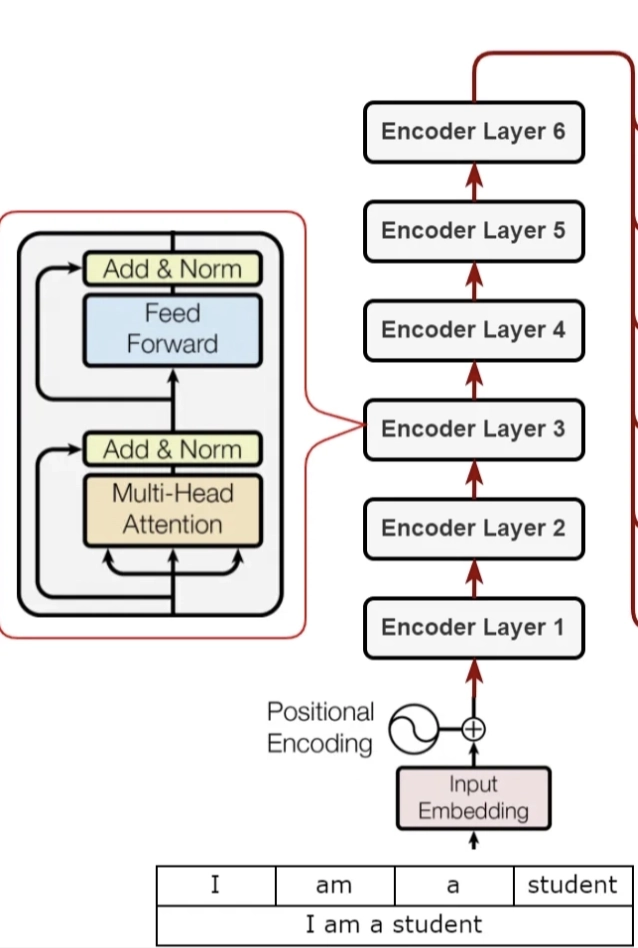 | Decoder 층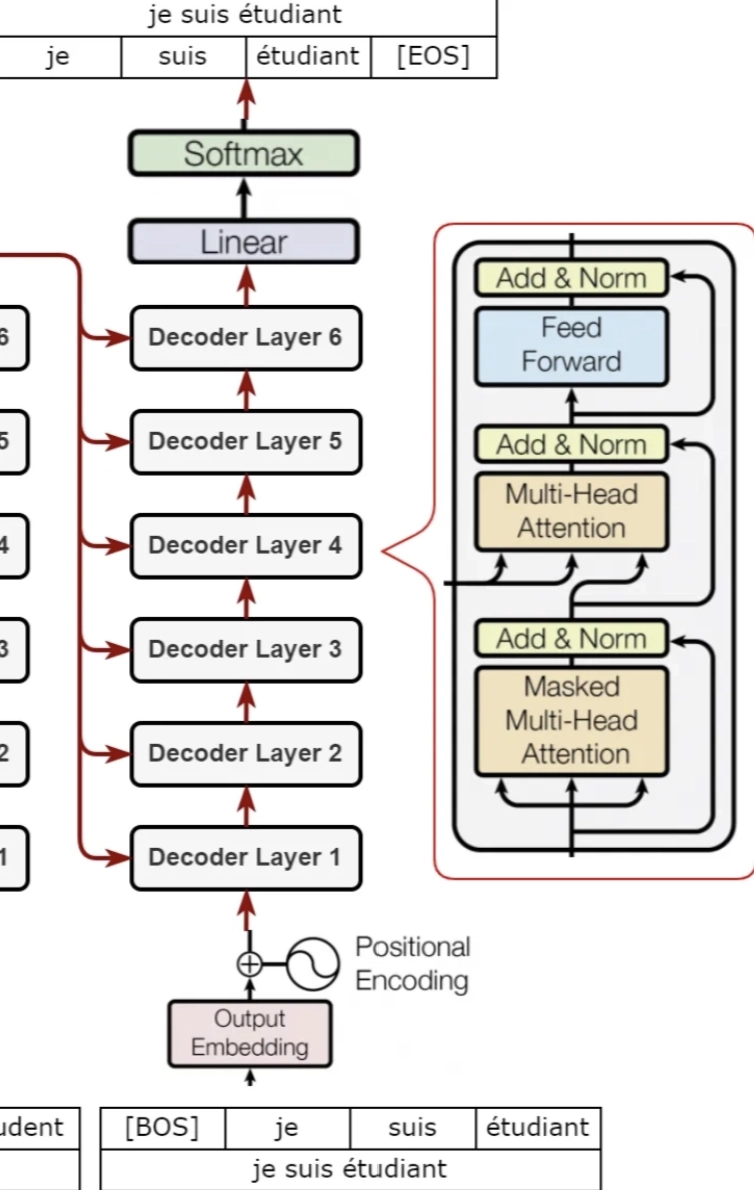 |
| --- | --- | --- |
| 부품 1 | Multi-Head Self-Attention: 원문 단어끼리 문맥 파악 | Masked Self-Attention: 지금까지 쓴 단어끼리 관계 파악 (미래 단어는 가림) |
| 부품 2 | Feed-Forward Network: 단어마다 따로 더 깊이 가공 | Cross-Attention: 인코더 출력에서 필요한 부분 찾기 |
| 부품 3 | | Feed-Forward Network |
| 최종 출력 | 단어별 문맥 벡터 전부 (디코더의 K, V로 전달) | Linear + Softmax로 다음 단어 확률 계산 |

- Feed-Forward Network: 벡터를 넓혔다 좁히며 단어 하나씩 다듬음. 단어끼리 정보를 주고받지 않음.
    - Self-Attention = 조별 토론, FFN = 토론 후 같은 선생님에게 받는 1:1 첨삭.
- Add & Norm: 모든 부품 뒤에 붙는 안전장치.
    - Add (잔차 연결): 결과에 원래 입력을 더함. 원본은 두고 수정 사항만 덧붙임 (ResNet 아이디어).
    - Norm (층 정규화): 값의 크기를 일정하게 맞춰 학습을 안정적이고 빠르게 함.
- Masked: 학습 때 정답 문장을 한 번에 넣기 때문에, 가리지 않으면 답을 미리 보는 "컨닝"이 됨.